<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/2_1_svd_geometry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2.1 · The SVD: rotate, scale, rotate

*Phase 2 — SVD, and what it tells us about a matrix*

Phase 1 gave us eigenvectors: directions a matrix only scales. They were a powerful idea, but three things limited them. They need a **square** matrix. For a general matrix they are **not perpendicular**, which makes the picture messy. And for some matrices (the shear in 1.4) there are **too few** of them.

The singular value decomposition (SVD) removes all three limits. It exists for **every** matrix of **any** shape, and its two sets of directions are always perpendicular. It does this by asking a slightly different question. Instead of "which directions are only scaled?", it asks "which *perpendicular* input directions are sent to *perpendicular* output directions?" The answer is

$$A = U\,\Sigma\,V^\top$$

with $V$ and $U$ orthogonal (rotations, possibly with reflections) and $\Sigma$ diagonal with non-negative entries $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$, the **singular values**. Rotate, scale along the axes, rotate again.

This is the tool we'll use on weight matrices, which are almost never square or symmetric, so it is the one that matters most for interpretability. As before, each step is a short note followed by one experiment cell. All numerics are PyTorch; matplotlib only draws.

1. Where eigenvectors fall short
2. The geometric picture: circle to ellipse
3. Rotate, scale, rotate
4. Where the singular values come from
5. Rectangular matrices
6. Reading the singular values
7. The SVD versus the eigendecomposition

## Setup

Same conventions as Phase 1, and the same matrix $A$ as notebook 1.1, so we can compare its SVD directly with its eigenvectors. Colours: orange and purple mark the first and second singular direction (the pair $v_i \to u_i$ share a colour), blue is the image of the unit circle, grey is reference, and black dashed lines are eigen-directions, which we use for contrast.

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

C_IN, C_OUT = "#6b7280", "#2563eb"          # reference (grey), image of the unit circle (blue)
C_S1, C_S2 = "#d97706", "#9333ea"           # first and second singular direction (orange, purple)
SV_COLORS = [C_S1, C_S2]

theta = torch.linspace(0, 2 * math.pi, 400)
circle = torch.stack([theta.cos(), theta.sin()])

A = torch.tensor([[2.0, 1.0],
                  [0.5, 1.5]])               # the matrix from notebook 1.1


def eig_sym(S):
    """Eigen-decomposition of a symmetric matrix, largest eigenvalue first."""
    lam, Q = torch.linalg.eigh(S)
    order = lam.argsort(descending=True)
    return lam[order], Q[:, order]


def line_angle_deg(u, v):
    """Angle in degrees between two directions, treated as lines (so v and −v are the same)."""
    u, v = u / u.norm(), v / v.norm()
    if (u @ v) < 0:
        v = -v
    return math.degrees(2 * torch.atan2((u - v).norm(), (u + v).norm()).item())


def svd_proper(M):
    """SVD of a 2×2 matrix with det > 0, with signs chosen so U and V are both proper rotations (det = +1).
    Returns U, s, V (note: V, not Vᵀ)."""
    U, s, Vh = torch.linalg.svd(M)
    U, V = U.clone(), Vh.T.clone()
    if U[0, 0] < 0:                            # make u₁ point rightwards (flip the pair u₁, v₁ together)
        U[:, 0], V[:, 0] = -U[:, 0], -V[:, 0]
    if torch.det(U) < 0:                       # det U = det V when det M > 0, so flip the second pair too
        U[:, 1], V[:, 1] = -U[:, 1], -V[:, 1]
    assert torch.det(U) > 0 and torch.det(V) > 0
    return U, s, V


def grid_segments(lim=1.0, step=0.5, n=41):
    """Lattice lines x = k and y = k for k in [-lim, lim], each as a (2, n) tensor of points."""
    t = torch.linspace(-lim, lim, n)
    ones = torch.ones(n)
    segs = []
    for k in torch.arange(-lim, lim + 1e-9, step):
        segs.append(torch.stack([k * ones, t]))
        segs.append(torch.stack([t, k * ones]))
    return segs


def draw_space(ax, M, title, lim=3.5):
    """Lattice and unit circle after applying M (pass the identity for 'before')."""
    for i, s_ in enumerate(grid_segments()):
        p = M @ s_
        ax.plot(p[0], p[1], color=C_IN, lw=0.7, alpha=0.45, label="lattice" if i == 0 else None)
    c = M @ circle
    ax.plot(c[0], c[1], color=C_OUT, lw=2, label="unit circle")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal"); ax.grid(False)
    ax.axhline(0, color="k", lw=0.4, zorder=0); ax.axvline(0, color="k", lw=0.4, zorder=0)
    ax.set_title(title)


def draw_vec(ax, v, label, color, offset=(8, 4), ha="left", lw=2.4):
    """Arrow from the origin to v, with a label next to the tip."""
    tip = v.tolist()
    ax.annotate("", xy=tip, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=lw), zorder=6)
    ax.annotate(label, xy=tip, xytext=offset, textcoords="offset points", ha=ha, fontsize=10, weight="bold", zorder=7,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))


print("torch", torch.__version__)

torch 2.11.0+cpu


## Step 1 · Where eigenvectors fall short

Let's see the three limitations concretely, each in one line of code.

1. A $3\times 2$ matrix maps the plane into 3-space. "Which direction is only scaled?" makes no sense when the input and output live in different spaces, and the eigenvalue solver refuses.
2. For the matrix $A$ from 1.1 the eigenvectors exist but are not perpendicular, so they do not give a clean orthogonal frame.
3. For the shear from 1.4 there are not enough eigenvectors: the eigenvector matrix is singular.

In [2]:
B_tall = torch.tensor([[2.0, 0.0],
                       [1.0, 1.0],
                       [0.0, 1.5]])                      # maps R² → R³

try:
    torch.linalg.eig(B_tall)
except RuntimeError as e:
    print("1) eig on a 3×2 matrix:", str(e).splitlines()[0])

VA = torch.linalg.eig(A).eigenvectors.real
print(f"\n2) eigenvectors of A are {line_angle_deg(VA[:, 0], VA[:, 1]):.1f}° apart (perpendicular would be 90°)")

J = torch.tensor([[1.0, 1.0], [0.0, 1.0]])
print(f"\n3) the shear's eigenvector matrix has condition number {torch.linalg.cond(torch.linalg.eig(J).eigenvectors.real):.1e}: it is singular")

1) eig on a 3×2 matrix: linalg.eig: A must be batches of square matrices, but they are 3 by 2 matrices

2) eigenvectors of A are 71.6° apart (perpendicular would be 90°)

3) the shear's eigenvector matrix has condition number 9.0e+15: it is singular


## Step 2 · The geometric picture: circle to ellipse

Every matrix sends the unit circle to an ellipse (in 1.1 and 1.2 we saw this again and again). An ellipse has two perpendicular axes, and the SVD simply reads them off:

- the **semi-axis lengths** are the singular values $\sigma_1 \ge \sigma_2$;
- the **axis directions** are the left singular vectors $u_1, u_2$ (perpendicular, in the output space);
- the input directions that land on those axes are the right singular vectors $v_1, v_2$ (perpendicular, in the input space), related by

$$A v_i = \sigma_i\, u_i$$

So the SVD answers the question we posed: $v_1 \perp v_2$ go to $\sigma_1 u_1 \perp \sigma_2 u_2$. Unlike an eigenvector, $v_i$ and $u_i$ are different vectors, but each is a perfect unit-length perpendicular frame.

We'll compute it with `torch.linalg.svd`, check $Av_i = \sigma_i u_i$, and confirm independently, by brute force over the image of the circle, that the farthest and nearest points of the ellipse are exactly $\pm\sigma_1 u_1$ and $\pm\sigma_2 u_2$.

singular values: tensor([2.5583, 0.9772])
A v1 = [2.176250899482821, 1.3449970239279148]      σ1 u1 = [2.176250899482822, 1.3449970239279148]
A v2 = [-0.513743148373008, 0.8312538755549066]      σ2 u2 = [-0.5137431483730078, 0.8312538755549068]

v₁·v₂ = 0.0e+00     u₁·u₂ = -1.7e-16   (both pairs perpendicular)

farthest point of the ellipse: 2.5583 from the origin (σ₁ = 2.5583), reached from an input 0.001° off v₁
nearest point of the ellipse : 0.9772 from the origin (σ₂ = 0.9772), reached from an input 0.001° off v₂


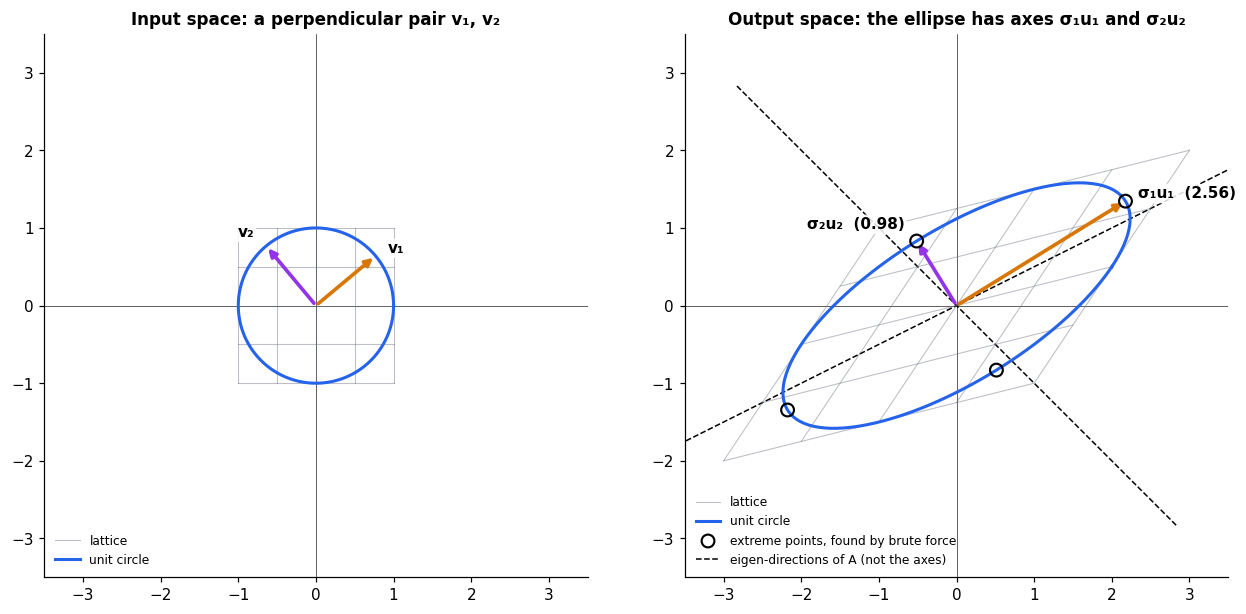

In [3]:
U, s, V = svd_proper(A)                              # columns of U: left singular vectors; columns of V: right singular vectors
print("singular values:", s)
for i in range(2):
    print(f"A v{i+1} = {(A @ V[:, i]).tolist()}      σ{i+1} u{i+1} = {(s[i] * U[:, i]).tolist()}")
assert torch.allclose(A @ V, U * s)                  # A V = U Σ

print(f"\nv₁·v₂ = {(V[:, 0] @ V[:, 1]).item():.1e}     u₁·u₂ = {(U[:, 0] @ U[:, 1]).item():.1e}   (both pairs perpendicular)")

# brute force: walk around the unit circle, look at the image, and find its farthest and nearest points
t = torch.linspace(0, 2 * math.pi, 40000)
inp = torch.stack([t.cos(), t.sin()])
img = A @ inp
r = img.norm(dim=0)
far, near = r.argmax(), r.argmin()
print(f"\nfarthest point of the ellipse: {r[far]:.4f} from the origin (σ₁ = {s[0]:.4f}), reached from an input {line_angle_deg(inp[:, far], V[:, 0]):.3f}° off v₁")
print(f"nearest point of the ellipse : {r[near]:.4f} from the origin (σ₂ = {s[1]:.4f}), reached from an input {line_angle_deg(inp[:, near], V[:, 1]):.3f}° off v₂")
assert abs(r[far] - s[0]) < 1e-6 and abs(r[near] - s[1]) < 1e-6
assert line_angle_deg(inp[:, far], V[:, 0]) < 0.05 and line_angle_deg(inp[:, near], V[:, 1]) < 0.05

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
draw_space(axes[0], torch.eye(2), "Input space: a perpendicular pair v₁, v₂")
draw_vec(axes[0], V[:, 0], "v₁", C_S1, offset=(8, 2))
draw_vec(axes[0], V[:, 1], "v₂", C_S2, offset=(-8, 6), ha="right")
axes[0].legend(loc="lower left", fontsize=8, frameon=False)

draw_space(axes[1], A, "Output space: the ellipse has axes σ₁u₁ and σ₂u₂")
for i, lab in enumerate([f"σ₁u₁  ({s[0]:.2f})", f"σ₂u₂  ({s[1]:.2f})"]):
    draw_vec(axes[1], s[i] * U[:, i], lab, SV_COLORS[i], offset=(8, 2) if i == 0 else (-8, 8), ha="left" if i == 0 else "right")
for P in (img[:, far], img[:, near]):
    axes[1].scatter([P[0], -P[0]], [P[1], -P[1]], s=70, facecolors="none", edgecolors="black", linewidths=1.4, zorder=8)
axes[1].scatter([], [], s=70, facecolors="none", edgecolors="black", linewidths=1.4, label="extreme points, found by brute force")
for k in range(2):                                  # the eigen-directions of A, for contrast: not the ellipse axes
    w = VA[:, k] / VA[:, k].norm()
    axes[1].plot([-4 * w[0], 4 * w[0]], [-4 * w[1], 4 * w[1]], color="black", ls="--", lw=1.0, zorder=1,
                 label="eigen-directions of A (not the axes)" if k == 0 else None)
axes[1].legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## Step 3 · Rotate, scale, rotate

Read $A = U\Sigma V^\top$ from right to left, as we did for $A = V\Lambda V^{-1}$ in 1.1:

1. $V^\top$ rotates the input so that $v_1, v_2$ land on the coordinate axes. (Because $V$ is orthogonal, $V^{-1} = V^\top$.)
2. $\Sigma$ stretches the axes, by $\sigma_1$ along the first and $\sigma_2$ along the second.
3. $U$ rotates the result so that the axes land on $u_1, u_2$.

The eigendecomposition used the *same* basis on both sides ($V$ and $V^{-1}$). The SVD uses two *different* orthogonal bases, one for the input and one for the output, and that freedom is exactly what lets it work for every matrix. The picture below applies the three factors one at a time, tracking $v_1$ and $v_2$ as they move.

det U = 1.0   det V = 1.0   (both proper rotations)
|det A| = 2.5000   σ₁σ₂ = 2.5000   (rotations don't change area, Σ scales it by σ₁σ₂)


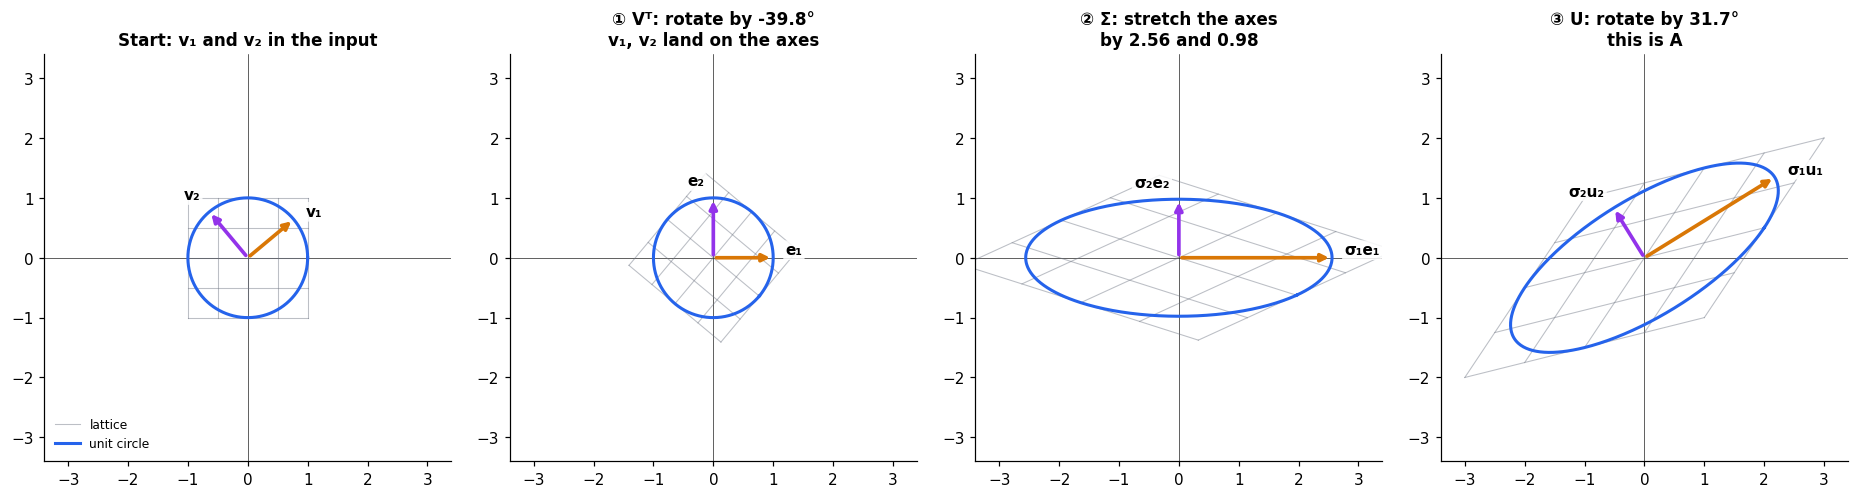

In [4]:
Sigma = torch.diag(s)
assert torch.allclose(U @ Sigma @ V.T, A)
print("det U =", round(torch.det(U).item(), 6), "  det V =", round(torch.det(V).item(), 6), "  (both proper rotations)")
print(f"|det A| = {abs(torch.det(A)).item():.4f}   σ₁σ₂ = {(s[0] * s[1]).item():.4f}   (rotations don't change area, Σ scales it by σ₁σ₂)")
ang_V = math.degrees(math.atan2(V[1, 0].item(), V[0, 0].item()))
ang_U = math.degrees(math.atan2(U[1, 0].item(), U[0, 0].item()))

stages = [
    (torch.eye(2),       "Start: v₁ and v₂ in the input",       ["v₁", "v₂"]),
    (V.T,                f"① Vᵀ: rotate by {-ang_V:.1f}°\nv₁, v₂ land on the axes", ["e₁", "e₂"]),
    (Sigma @ V.T,        f"② Σ: stretch the axes\nby {s[0]:.2f} and {s[1]:.2f}",   ["σ₁e₁", "σ₂e₂"]),
    (U @ Sigma @ V.T,    f"③ U: rotate by {ang_U:.1f}°\nthis is A",     ["σ₁u₁", "σ₂u₂"]),
]
assert torch.allclose(stages[3][0], A)

fig, axes = plt.subplots(1, 4, figsize=(17, 5))
for ax, (M, title, labels) in zip(axes, stages):
    draw_space(ax, M, title, lim=3.4)
    for i in range(2):
        draw_vec(ax, M @ V[:, i], labels[i], SV_COLORS[i], offset=(8, 2) if i == 0 else (-6, 8), ha="left" if i == 0 else "right")
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## Step 4 · Where the singular values come from

The SVD is not a separate piece of machinery. It is the spectral theorem from 1.2, applied to a symmetric matrix we can always build from $A$. Substitute $A = U\Sigma V^\top$ and use $U^\top U = I$:

$$A^\top A = V\Sigma^\top U^\top U \Sigma V^\top = V\,\Sigma^2\,V^\top \qquad\text{and likewise}\qquad AA^\top = U\,\Sigma^2\,U^\top$$

So $V$ holds the eigenvectors of $A^\top A$, $U$ holds the eigenvectors of $AA^\top$, and the squared singular values $\sigma_i^2$ are their eigenvalues. Both matrices are symmetric and positive semi-definite (they are Gram matrices, as in 1.2 Step 7), which is why the singular values are real and non-negative and the singular vectors are perpendicular. This is also how the SVD computes the stretch of any direction:

$$\lVert Ax\rVert^2 = x^\top (A^\top A)\, x$$

the quadratic form from 1.2 Step 6. On unit vectors it peaks at $\sigma_1^2$ along $v_1$ and bottoms out at $\sigma_2^2$ along $v_2$.

AᵀA =
 tensor([[4.2500, 2.7500],
        [2.7500, 3.2500]])

eigenvalues of AᵀA : tensor([6.5451, 0.9549])
eigenvalues of AAᵀ : tensor([6.5451, 0.9549])
singular values²   : tensor([6.5451, 0.9549])
✓ V = eigenvectors of AᵀA,  U = eigenvectors of AAᵀ,  σ² = their eigenvalues

largest stretch over all directions: 2.5583   (σ₁ = 2.5583)
smallest stretch over all directions: 0.9772   (σ₂ = 0.9772)


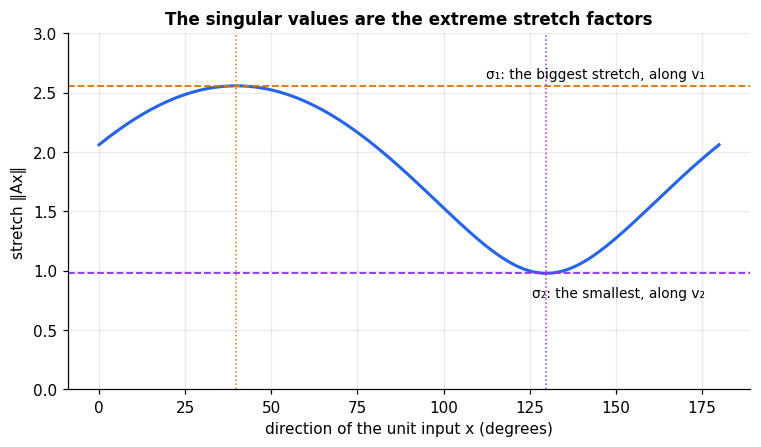

In [5]:
AtA, AAt = A.T @ A, A @ A.T
lam_v, Qv = eig_sym(AtA)
lam_u, Qu = eig_sym(AAt)
print("AᵀA =\n", AtA)
print("\neigenvalues of AᵀA :", lam_v)
print("eigenvalues of AAᵀ :", lam_u)
print("singular values²   :", s ** 2)
assert torch.allclose(lam_v, s ** 2) and torch.allclose(lam_u, s ** 2)
assert torch.allclose(Qv.abs(), V.abs()) and torch.allclose(Qu.abs(), U.abs())      # same vectors, up to sign
print("✓ V = eigenvectors of AᵀA,  U = eigenvectors of AAᵀ,  σ² = their eigenvalues")

# how much does A stretch each direction?
thetas = torch.linspace(0, math.pi, 721)
X_ = torch.stack([thetas.cos(), thetas.sin()])
stretch = (A @ X_).norm(dim=0)                                   # ‖Ax‖ for every unit vector x
assert torch.allclose(stretch ** 2, (X_ * (AtA @ X_)).sum(0))    # ‖Ax‖² = xᵀ(AᵀA)x
print(f"\nlargest stretch over all directions: {stretch.max():.4f}   (σ₁ = {s[0]:.4f})")
print(f"smallest stretch over all directions: {stretch.min():.4f}   (σ₂ = {s[1]:.4f})")
assert abs(stretch.max() - s[0]) < 1e-4 and abs(stretch.min() - s[1]) < 1e-4

th_v = [math.degrees(math.atan2(V[1, i].item(), V[0, i].item())) % 180 for i in range(2)]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(torch.rad2deg(thetas), stretch, color=C_OUT, lw=2)
for i in range(2):
    ax.axhline(s[i].item(), color=SV_COLORS[i], ls="--", lw=1.2)
    ax.axvline(th_v[i], color=SV_COLORS[i], ls=":", lw=1.0)
ax.text(176, s[0].item() + 0.06, "σ₁: the biggest stretch, along v₁", ha="right", fontsize=9)
ax.text(176, s[1].item() - 0.2, "σ₂: the smallest, along v₂", ha="right", fontsize=9)
ax.set_ylim(0, 3); ax.set_xlabel("direction of the unit input x (degrees)"); ax.set_ylabel("stretch ‖Ax‖")
ax.set_title("The singular values are the extreme stretch factors")
plt.show()

## Step 5 · Rectangular matrices

Nothing above needed $A$ to be square. For an $m \times n$ matrix, $V$ is $n\times n$ (an orthonormal basis of the input space), $U$ is $m\times m$ (an orthonormal basis of the output space), and $\Sigma$ is $m \times n$ with the $k = \min(m,n)$ singular values on its diagonal and zeros elsewhere. Because most of $\Sigma$ is zeros, a leaner **thin** (or reduced) SVD is usually used: keep only the $k$ columns of $U$ and $V$ that meet a singular value. Then $U$ is $m\times k$, $\Sigma$ is $k\times k$ and $V^\top$ is $k \times n$.

Let's look at the shapes for a tall, a square and a wide matrix, and confirm both versions rebuild the matrix.

In [6]:
print(f"{'':<8}{'M':>7}   {'full: U':>10}{'Σ':>9}{'Vᵀ':>9}   {'thin: U':>10}{'Σ (k×k)':>10}{'Vᵀ':>9}")
for name, (m, n) in [("tall", (5, 3)), ("square", (4, 4)), ("wide", (3, 5))]:
    M = torch.randn(m, n)
    k = min(m, n)
    Uf, sf, Vhf = torch.linalg.svd(M, full_matrices=True)
    Ut, st, Vht = torch.linalg.svd(M, full_matrices=False)
    Sig_full = torch.zeros(m, n); Sig_full[:k, :k] = torch.diag(sf)               # pad the singular values into an m×n matrix
    assert torch.allclose(Uf @ Sig_full @ Vhf, M) and torch.allclose(Ut @ torch.diag(st) @ Vht, M)
    fmt = lambda T: f"{T.shape[0]}×{T.shape[1]}"
    print(f"{name:<8}{fmt(M):>7}   {fmt(Uf):>10}{fmt(Sig_full):>9}{fmt(Vhf):>9}   {fmt(Ut):>10}{f'{k}×{k}':>10}{fmt(Vht):>9}")
print("✓ both versions rebuild M exactly")

              M      full: U        Σ       Vᵀ      thin: U   Σ (k×k)       Vᵀ
tall        5×3          5×5      5×3      3×3          5×3       3×3      3×3
square      4×4          4×4      4×4      4×4          4×4       4×4      4×4
wide        3×5          3×3      3×5      5×5          3×3       3×3      3×5
✓ both versions rebuild M exactly


The $3\times2$ matrix from Step 1 makes the geometry visible. It sends the plane into 3-space, so the image of the unit circle is an ellipse *lying in a flat plane inside $\mathbb{R}^3$*. Its two axes are $\sigma_1 u_1$ and $\sigma_2 u_2$, and the plane they span is the only part of 3-space the matrix can reach. The third left singular vector $u_3$ from the full SVD is the direction the matrix never touches.

singular values of the 3×2 matrix: tensor([2.3353, 1.6722])
u₃ is perpendicular to every column of B: True


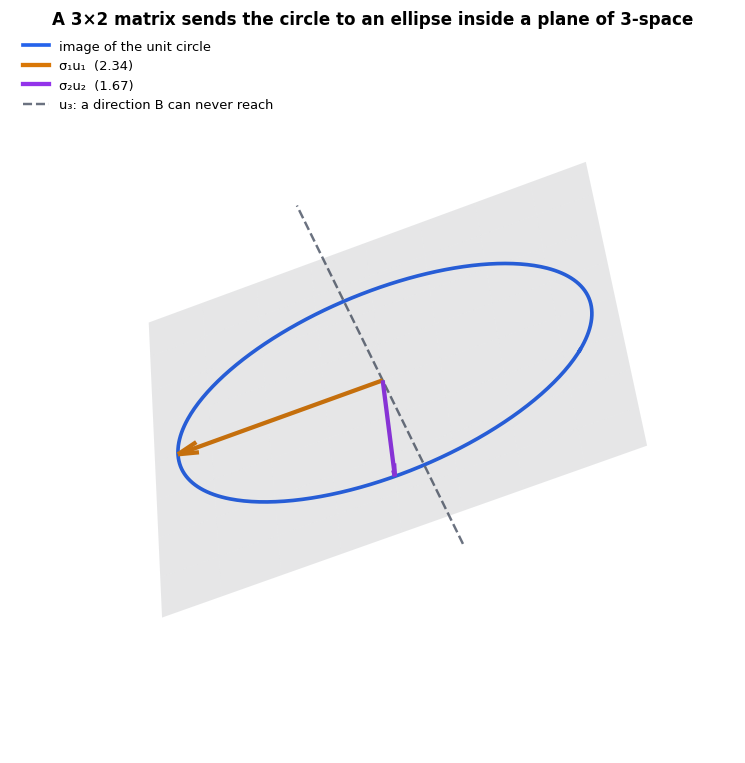

In [7]:
Ub, sb, Vhb = torch.linalg.svd(B_tall, full_matrices=False)     # thin: U is 3×2
Uf3, _, _ = torch.linalg.svd(B_tall, full_matrices=True)        # full: adds the unreachable third direction
u3 = Uf3[:, 2]
print("singular values of the 3×2 matrix:", sb)
print("u₃ is perpendicular to every column of B:", torch.allclose(B_tall.T @ u3, torch.zeros(2), atol=1e-12))

ellipse = B_tall @ circle                                        # (3, 400): the image of the unit circle
assert (u3 @ ellipse).abs().max() < 1e-12                        # the ellipse lies entirely in the plane ⟂ u₃

fig = plt.figure(figsize=(8.5, 7))
ax = fig.add_subplot(projection="3d")
g = torch.linspace(-2.6, 2.6, 9)
a_, b_ = torch.meshgrid(g, g, indexing="ij")
Pt = a_[..., None] * Ub[:, 0] + b_[..., None] * Ub[:, 1]
ax.plot_surface(Pt[..., 0].numpy(), Pt[..., 1].numpy(), Pt[..., 2].numpy(), color=C_IN, alpha=0.12, linewidth=0)
ax.plot(ellipse[0].numpy(), ellipse[1].numpy(), ellipse[2].numpy(), color=C_OUT, lw=2.4)
for i in range(2):
    ax.quiver(0, 0, 0, *(sb[i] * Ub[:, i]).tolist(), color=SV_COLORS[i], linewidth=2.8, arrow_length_ratio=0.1)
ax.plot([-2.4 * u3[0].item(), 2.4 * u3[0].item()], [-2.4 * u3[1].item(), 2.4 * u3[1].item()],
        [-2.4 * u3[2].item(), 2.4 * u3[2].item()], color=C_IN, ls="--", lw=1.6)
ax.plot([], [], [], color=C_OUT, lw=2.4, label="image of the unit circle")
ax.plot([], [], [], color=C_S1, lw=2.8, label=f"σ₁u₁  ({sb[0]:.2f})")
ax.plot([], [], [], color=C_S2, lw=2.8, label=f"σ₂u₂  ({sb[1]:.2f})")
ax.plot([], [], [], color=C_IN, ls="--", lw=1.6, label="u₃: a direction B can never reach")
ax.legend(loc="upper left", fontsize=8.5, frameon=False)
ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6); ax.set_zlim(-2.6, 2.6)
ax.set_box_aspect((1, 1, 1), zoom=1.15); ax.set_axis_off(); el = math.degrees(math.asin(abs(u3[2].item())))     # look down the normal u₃ of the plane, tilted a little
az = math.degrees(math.atan2(u3[1].item(), u3[0].item()))
ax.view_init(elev=min(el, 90) - 50 if u3[2] > 0 else 50 - min(el, 90), azim=az + 25)
ax.set_title("A 3×2 matrix sends the circle to an ellipse inside a plane of 3-space", pad=0)
fig.subplots_adjust(left=0, right=1, bottom=0, top=0.94)
plt.show()

The wide case is the mirror image. A $2\times 3$ matrix maps 3-space onto the plane, so it must collapse one input direction entirely. In the full SVD that direction is the third right singular vector $v_3$, which has no singular value to pair with and is sent to zero. Making this precise (rank, null space, row and column spaces) is the subject of notebook 2.2.

In [8]:
Wd = torch.randn(2, 3)                                  # maps R³ → R²
Uw, sw, Vhw = torch.linalg.svd(Wd)                      # full SVD: Vᵀ is 3×3
print("singular values (only two):", sw)
print(f"‖Wd v₃‖ = {(Wd @ Vhw[2]).norm().item():.1e}   (the third right singular vector is sent to zero)")
assert (Wd @ Vhw[2]).norm() < 1e-12

singular values (only two): tensor([2.2155, 0.0371])
‖Wd v₃‖ = 3.6e-16   (the third right singular vector is sent to zero)


## Step 6 · Reading the singular values

The singular values summarise how a matrix acts, in several equivalent ways. With $k = \min(m,n)$ of them:

| Quantity | In terms of $\sigma_i$ | Meaning |
|---|---|---|
| Operator (spectral) norm $\max_x \lVert Mx\rVert/\lVert x\rVert$ | $\sigma_1$ | biggest possible stretch |
| Smallest stretch of a full-rank square matrix | $\sigma_k$ | smallest stretch |
| Condition number | $\sigma_1/\sigma_k$ | how lopsided the stretching is |
| Frobenius norm squared $\sum_{ij} M_{ij}^2$ | $\sum_i \sigma_i^2$ | total "energy" |
| Nuclear norm | $\sum_i \sigma_i$ | |
| $\lvert\det M\rvert$ (square) | $\prod_i \sigma_i$ | volume scaling |

The Frobenius line is the same statement as "trace = total variance" from 1.3: the energy of a matrix is shared out among its singular values exactly as variance is shared among principal components. We'll check each on a random $5 \times 4$ matrix, plus the determinant on our 2×2 $A$.

In [9]:
torch.manual_seed(2)
M = torch.randn(5, 4)
sM = torch.linalg.svdvals(M)
print("singular values:", sM)

x = torch.randn(4, 100000); x = x / x.norm(dim=0)
stretch_M = (M @ x).norm(dim=0)
print(f"\nbiggest stretch among 100000 random directions : {stretch_M.max():.4f}     σ₁ = {sM[0]:.4f}")
print(f"smallest stretch among 100000 random directions: {stretch_M.min():.4f}     σ₄ = {sM[-1]:.4f}")
assert stretch_M.max() <= sM[0] + 1e-9 and stretch_M.min() >= sM[-1] - 1e-9

print(f"\noperator norm        {torch.linalg.matrix_norm(M, 2):.4f}   =  σ₁          {sM[0]:.4f}")
print(f"Frobenius norm²      {(M ** 2).sum():.4f}   =  Σσ²         {(sM ** 2).sum():.4f}")
print(f"nuclear norm         {torch.linalg.matrix_norm(M, 'nuc'):.4f}   =  Σσ          {sM.sum():.4f}")
print(f"condition number     {torch.linalg.cond(M):.4f}   =  σ₁/σ₄       {sM[0] / sM[-1]:.4f}")
print(f"|det A| (2×2 A)     {abs(torch.det(A)):.4f}   =  σ₁σ₂        {s[0] * s[1]:.4f}")
assert torch.allclose(torch.linalg.matrix_norm(M, 2), sM[0]) and torch.allclose((M ** 2).sum(), (sM ** 2).sum())
assert torch.allclose(torch.linalg.matrix_norm(M, "nuc"), sM.sum()) and torch.allclose(torch.linalg.cond(M), sM[0] / sM[-1])
assert torch.allclose(abs(torch.det(A)), s[0] * s[1])

singular values: tensor([3.3815, 2.5372, 1.0425, 0.5102])

biggest stretch among 100000 random directions : 3.3807     σ₁ = 3.3815
smallest stretch among 100000 random directions: 0.5130     σ₄ = 0.5102

operator norm        3.3815   =  σ₁          3.3815
Frobenius norm²      19.2189   =  Σσ²         19.2189
nuclear norm         7.4714   =  Σσ          7.4714
condition number     6.6281   =  σ₁/σ₄       6.6281
|det A| (2×2 A)     2.5000   =  σ₁σ₂        2.5000


One more way to read the SVD, and the one we'll use most. Multiplying out $U\Sigma V^\top$ column by column gives a **sum of rank-one pieces**, each an outer product weighted by a singular value:

$$A = \sum_{i=1}^{k} \sigma_i\, u_i v_i^\top$$

Each piece $u_iv_i^\top$ takes the input component along $v_i$ and writes it along $u_i$, and $\sigma_i$ says how loudly. Pieces with small $\sigma_i$ contribute little. Dropping them is a low-rank approximation, which is the subject of notebook 2.3. Here is the decomposition for our $2\times 2$, and a first look at what dropping the second piece costs.

In [10]:
pieces = [s[i] * torch.outer(U[:, i], V[:, i]) for i in range(2)]
for i, Pm in enumerate(pieces):
    print(f"σ{i+1} u{i+1} v{i+1}ᵀ =\n", Pm, f"\n   rank = {torch.linalg.matrix_rank(Pm).item()}\n")
assert torch.allclose(pieces[0] + pieces[1], A)
print("✓ A = σ₁u₁v₁ᵀ + σ₂u₂v₂ᵀ")

err = (A - pieces[0]).norm()
print(f"\nkeeping only the first piece leaves an error of ‖A − σ₁u₁v₁ᵀ‖_F = {err:.4f},  which equals σ₂ = {s[1]:.4f}")
assert torch.allclose(err, s[1])

σ1 u1 v1ᵀ =
 tensor([[1.6708, 1.3944],
        [1.0326, 0.8618]]) 
   rank = 1

σ2 u2 v2ᵀ =
 tensor([[ 0.3292, -0.3944],
        [-0.5326,  0.6382]]) 
   rank = 1

✓ A = σ₁u₁v₁ᵀ + σ₂u₂v₂ᵀ

keeping only the first piece leaves an error of ‖A − σ₁u₁v₁ᵀ‖_F = 0.9772,  which equals σ₂ = 0.9772


## Step 7 · The SVD versus the eigendecomposition

For a square matrix we now have two decompositions. How do they relate?

- **Symmetric, positive semi-definite** (a covariance matrix, say): they coincide. $U = V$ and $\sigma_i = \lambda_i$.
- **Symmetric but indefinite:** the singular values are the absolute values of the eigenvalues, $\sigma_i = |\lambda_i|$, and for each negative eigenvalue $u_i = -v_i$. The matrix flips that direction, and an SVD records the flip as a sign difference between the input and output vectors.
- **Non-symmetric:** the two are genuinely different. The eigenvectors are not perpendicular and the eigenvalues are not the stretch factors. (One thing survives: $\prod|\lambda_i| = |\det| = \prod\sigma_i$, though the individual numbers differ.)

A handy diagnostic is the dot product $u_i\cdot v_i$: $+1$ when direction $i$ is merely stretched, $-1$ when it is flipped. Let's check all three.

In [11]:
S = torch.tensor([[5.0, 2.0], [2.0, 2.0]])               # symmetric PSD (the S from 1.2 and the covariance from 1.3)
Ind = torch.tensor([[1.0, 2.0], [2.0, 1.0]])             # symmetric indefinite: eigenvalues 3 and −1

print(f"{'matrix':<28}{'eigenvalues':>18}{'singular values':>20}{'u·v per direction':>22}")
for name, Mx in [("symmetric PSD", S), ("symmetric indefinite", Ind), ("non-symmetric (A from 1.1)", A)]:
    ev = torch.linalg.eigvals(Mx).real
    ev = ev[ev.abs().argsort(descending=True)]
    Ux, sx, Vhx = torch.linalg.svd(Mx)
    uv = (Ux * Vhx.T).sum(0)                               # u_i · v_i
    print(f"{name:<28}{str([round(e, 3) for e in ev.tolist()]):>18}{str([round(v_, 3) for v_ in sx.tolist()]):>20}{str([round(d, 2) for d in uv.tolist()]):>22}")
    assert torch.allclose(abs(torch.linalg.det(Mx)), sx.prod()) and torch.allclose(ev.abs().prod(), sx.prod())
    if name != "non-symmetric (A from 1.1)":
        assert torch.allclose(ev.abs(), sx)                # σ = |λ| for any symmetric matrix

Ux, sx, Vhx = torch.linalg.svd(Ind)
assert torch.allclose((Ux * Vhx.T).sum(0), torch.tensor([1.0, -1.0]))
print("\nFor the indefinite matrix, u₂·v₂ = −1: the direction with eigenvalue −1 is flipped, and the SVD records that as a sign.")

matrix                             eigenvalues     singular values     u·v per direction
symmetric PSD                       [6.0, 1.0]          [6.0, 1.0]            [1.0, 1.0]
symmetric indefinite               [3.0, -1.0]          [3.0, 1.0]           [1.0, -1.0]
non-symmetric (A from 1.1)          [2.5, 1.0]      [2.558, 0.977]          [0.99, 0.99]

For the indefinite matrix, u₂·v₂ = −1: the direction with eigenvalue −1 is flipped, and the SVD records that as a sign.


A last connection to 1.4. A repeated eigenvalue made the eigenvectors non-unique, and a repeated *singular* value does the same to the singular vectors: only the subspace they span is determined, not the individual pair. The pentagon from 1.4 is the example that matters for us. Its $2 \times 5$ feature matrix has two equal singular values, so no orientation of the hidden space is singled out.

In [12]:
phis = 2 * math.pi * torch.arange(5) / 5
W = torch.stack([phis.cos(), phis.sin()])                  # the 2×5 pentagon from 1.4: five unit features in 2-D
sW = torch.linalg.svdvals(W)
print("singular values of the pentagon:", sW, "   √(5/2) =", math.sqrt(2.5))
assert torch.allclose(sW, torch.full((2,), math.sqrt(2.5)))

ph = math.radians(37)
R = torch.tensor([[math.cos(ph), -math.sin(ph)], [math.sin(ph), math.cos(ph)]])
print("after rotating the whole pentagon by 37°, the singular values are unchanged:", torch.allclose(torch.linalg.svdvals(R @ W), sW))

singular values of the pentagon: tensor([1.5811, 1.5811])    √(5/2) = 1.5811388300841898
after rotating the whole pentagon by 37°, the singular values are unchanged: True


## Try it yourself

1. **By hand.** Find the SVD of $\begin{pmatrix}3&0\\0&-2\end{pmatrix}$. Which of $U$ and $V$ carries the minus sign, and what are $\sigma_1, \sigma_2$?
2. **Via $A^\top A$.** For $\begin{pmatrix}3&0\\4&5\end{pmatrix}$, compute $A^\top A$ by hand, find its eigenvalues, and take square roots to get the singular values. Check that $\sigma_1\sigma_2 = |\det A|$.
3. **Thin shapes.** Take a random $6\times3$ matrix. Verify that the thin $U$ has orthonormal columns ($U^\top U = I$) but $UU^\top \neq I$. Why?
4. **Change the units.** Multiply the second column of $A$ by 10. How do the singular values change? Compare with how the eigenvalues change.
5. **Build to order.** Construct a $2\times2$ matrix with singular values $(4, 1)$, left singular vectors along $0°$ and $90°$ and right singular vectors along $30°$ and $120°$, as $U\Sigma V^\top$. Verify with `torch.linalg.svdvals`.

## What to carry forward

- The **SVD** $A = U\Sigma V^\top$ exists for every matrix, of any shape. It is a rotation, a scaling along the axes, and another rotation.
- Geometrically, $A$ sends the unit sphere to an ellipsoid. The **singular values** are its semi-axis lengths, the **left singular vectors** $u_i$ are its axes, and the **right singular vectors** $v_i$ are the perpendicular input directions that land on them: $Av_i = \sigma_i u_i$.
- It is the spectral theorem in disguise: $V$ and $\sigma_i^2$ are the eigenvectors and eigenvalues of $A^\top A$, and $U$ the eigenvectors of $AA^\top$.
- The singular values are the extreme stretch factors, and they give the operator norm ($\sigma_1$), the energy ($\sum\sigma_i^2$), the condition number and the volume scaling at a glance. $A = \sum_i \sigma_i u_i v_i^\top$ is a sum of rank-one pieces ordered by importance.
- For symmetric PSD matrices SVD and the eigendecomposition coincide; for symmetric indefinite ones $\sigma = |\lambda|$; for non-symmetric ones they differ. A repeated singular value makes the singular vectors non-unique, exactly as in 1.4.

**Next, notebook 2.2:** rank, the row, column and null spaces, and condition number: what the zero singular values and the tiny ones tell us.